# P1 — RSNA Knee: pipeline completo (Kaggle Notebook)

**Antes de correr** (panel derecho → *Settings*):
1. **Accelerator: GPU T4 x1** (no P100: las versiones recientes de PyTorch ya no la soportan).
2. **Internet: ON** (descarga pesos ImageNet y el modelo NLI; el texto de los reportes NO sale del notebook).
3. **Add Input → Competition → `rsna-knee-abnormality-detection`** (hay que haber aceptado las reglas con tu cuenta).
4. Subir la carpeta `03_scripts` como *Dataset* privado (`p1-scripts`) **o** clonar el repo de GitHub (celda 2).

Tiempo total estimado: 60–90 min. Cada celda deja log en `/kaggle/working/p1/02_logs/`.


In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, glob
print([p for p in glob.glob('/kaggle/input/*')])

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
['/kaggle/input/datasets', '/kaggle/input/competitions']


In [2]:
import os, glob
cand = []
for pat in ['/kaggle/input/*/config.py', '/kaggle/input/*/*/config.py',
            '/kaggle/input/*/*/*/config.py', '/kaggle/input/*/*/*/*/config.py']:
    cand += glob.glob(pat)
assert cand, 'No encuentro config.py: agrega el dataset de scripts con Add Input'
SCRIPTS = os.path.dirname(cand[0])
print('scripts en:', SCRIPTS)
!rm -rf /kaggle/working/scripts && cp -r "$SCRIPTS" /kaggle/working/scripts
%cd /kaggle/working/scripts
!ls


scripts en: /kaggle/input/datasets/kulipari/p1-rsna-rodilla-scripts
/kaggle/working/scripts
01_inventario_metadatos.py	    05_cache_dicom_25d.py      metricas.py
02b_extractor_nli_multilingue.py    06_entrenar_evaluar.py     p1lib.py
02_extractor_etiquetas_debiles.py   07_gradcam.py	       run_all.sh
03_validar_extractor_vs_dorados.py  08_tablas_para_informe.py
04_seleccion_subconjunto.py	    config.py


## 1. Metadatos y etiquetas débiles (Entregable 1)

In [3]:
!python 01_inventario_metadatos.py
!python 02_extractor_etiquetas_debiles.py
!python 04_seleccion_subconjunto.py

===== inicio 01_inventario_metadatos | 2026-10-30 08:08:36 | python 3.13.15 =====
datos en: /kaggle/input/competitions/rsna-knee-abnormality-detection
train.csv (4407, 14) columnas: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
train_series.csv (24371, 5) columnas: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']
n_estudios: 4407
n_series: 24371
n_dorados: 58
n_con_reporte: 4407
idiomas: {'en': 1740, 'es': 793, 'tr': 546, 'el': 321, 'de': 262, 'otro': 257, 'ru': 220, 'nl': 151, 'fr': 75, 'pt': 42}
idiomas_dorados: {'en': 28, 'es': 10, 'tr': 6, 'ru': 3, 'el': 3, 'otro': 3, 'nl': 2, 'de': 2, 'pt': 1}
prevalencia_dorados: {'ACL': 0.414, 'MCL': 0.155, 'Medial Meniscus': 0.448, 'Lateral Meniscus': 0.397, 'Medial OA': 0.259, 'Lateral OA': 0.19, 'PF OA': 0.362, 'Effusion': 0.603, 'Synovitis': 0.466, "Baker's":

In [4]:
# Opcional: segundo extractor (NLI multilingüe, pesos abiertos, ~10 min)
!python 02b_extractor_nli_multilingue.py
!python 03_validar_extractor_vs_dorados.py

===== inicio 02b_extractor_nli | 2026-10-30 08:08:59 | python 3.13.15 =====
reportes a procesar: 558
config.json: 100%|█████████████████████████| 1.09k/1.09k [00:00<00:00, 3.24MB/s]
tokenizer_config.json: 100%|███████████████████| 467/467 [00:00<00:00, 2.36MB/s]

spm.model: downloading bytes: ▏                             | 31.3kB            
spm.model: downloading bytes: ██████████████████████████████| 3.22MB,  311kB/s  
spm.model: reconstructing file: 100%|██████████████| 4.31MB / 4.31MB,  416kB/s  

tokenizer.json: downloading bytes: ███▏                     | 2.10MB            
tokenizer.json: downloading bytes: █████████████████████████| 5.72MB,  556kB/s  
tokenizer.json: reconstructing file: 100%|█████████| 16.3MB / 16.3MB, 1.59MB/s  
added_tokens.json: 100%|██████████████████████| 23.0/23.0 [00:00<00:00, 151kB/s]
special_tokens_map.json: 100%|██████████████████| 173/173 [00:00<00:00, 711kB/s]

model.safetensors: downloading bytes: ██████████████▎       |  363MB, 29.1MB/s  
model

## 2. DICOM → caché 2.5D

In [5]:
!python 05_cache_dicom_25d.py --slot sag_fluid
!python 05_cache_dicom_25d.py --slot cor_fluid

===== inicio 05_cache_sag_fluid | 2026-10-30 08:12:41 | python 3.13.15 =====
slot=sag_fluid estudios=556 workers=4 -> /kaggle/working/p1/cache/sag_fluid
  50/556
  100/556
  150/556
  200/556
  250/556
  300/556
  350/556
  400/556
  450/556
  500/556
  550/556
OK: 556/556 (100.0%)
fuente de lateralidad: {'geometria': 317, 'tag': 239}
===== inicio 05_cache_cor_fluid | 2026-10-30 08:13:30 | python 3.13.15 =====
slot=cor_fluid estudios=556 workers=4 -> /kaggle/working/p1/cache/cor_fluid
  50/556
  100/556
  150/556
  200/556
  250/556
  300/556
  350/556
  400/556
  450/556
  500/556
  550/556
OK: 554/556 (99.6%)
fuente de lateralidad: {'geometria': 316, 'tag': 238}
errores (muestra): ['sin_archivos', 'sin_archivos']


## 3. Arquitecturas (Entregable 2) — desde cero vs ImageNet

In [6]:
!python 06_entrenar_evaluar.py --run A1_scratch  --arch scratch --epochs 15
!python 06_entrenar_evaluar.py --run A2_resnet50 --arch resnet50

===== inicio runs/A1_scratch/train | 2026-10-30 08:14:16 | python 3.13.15 =====
dispositivo: cuda Tesla T4
train=425 val=75 dorado=56
fracción de etiquetas usadas (w>0): 1.000  peso medio: 0.678
pos_weight: {'ACL': np.float32(2.16), 'MCL': np.float32(2.38), 'Medial Meniscus': np.float32(1.38), 'Lateral Meniscus': np.float32(2.31), 'Medial OA': np.float32(1.92), 'Lateral OA': np.float32(2.57), 'PF OA': np.float32(1.92), 'Effusion': np.float32(1.03), 'Synovitis': np.float32(2.52), "Baker's": np.float32(1.75), 'Contusion': np.float32(1.71), 'Fracture': np.float32(2.91)}
/kaggle/working/scripts/06_entrenar_evaluar.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=dev.type == "cuda")
arch=scratch parámetros=1.91M lr_head=0.0003 lr_backbone=0.0003
ep 01 loss=0.8591 AUC_val(débil)=0.6203 t=0.2min
ep 02 loss=0.8495 AUC_val(débil)=0.5061 t=0.4min
ep 03 loss=0.8556 AU

## 4. Ablaciones (Entregable 4) y desbalance (Entregable 6)

In [7]:
!python 06_entrenar_evaluar.py --run B1_focal    --arch resnet50 --loss focal
!python 06_entrenar_evaluar.py --run B2_altaconf --arch resnet50 --ruido alta_conf
!python 06_entrenar_evaluar.py --run B3_coronal  --arch resnet50 --slot cor_fluid
!python 06_entrenar_evaluar.py --run C1_sin_posw --arch resnet50 --pos_weight none
!python 06_entrenar_evaluar.py --run C2_sampler  --arch resnet50 --sampler raros

===== inicio runs/B1_focal/train | 2026-10-30 08:19:17 | python 3.13.15 =====
dispositivo: cuda Tesla T4
train=425 val=75 dorado=56
fracción de etiquetas usadas (w>0): 1.000  peso medio: 0.678
pos_weight: {'ACL': np.float32(2.16), 'MCL': np.float32(2.38), 'Medial Meniscus': np.float32(1.38), 'Lateral Meniscus': np.float32(2.31), 'Medial OA': np.float32(1.92), 'Lateral OA': np.float32(2.57), 'PF OA': np.float32(1.92), 'Effusion': np.float32(1.03), 'Synovitis': np.float32(2.52), "Baker's": np.float32(1.75), 'Contusion': np.float32(1.71), 'Fracture': np.float32(2.91)}
/kaggle/working/scripts/06_entrenar_evaluar.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=dev.type == "cuda")
arch=resnet50 parámetros=23.80M lr_head=0.001 lr_backbone=0.0001
ep 01 loss=0.2164 AUC_val(débil)=0.5785 t=0.3min
ep 02 loss=0.2104 AUC_val(débil)=0.6054 t=0.7min
ep 03 loss=0.2010 AUC

## 5. Grad-CAM (Entregable 5) y tablas

In [8]:
!python 07_gradcam.py --run A2_resnet50
!python 07_gradcam.py --run A1_scratch
!python 08_tablas_para_informe.py --base A2_resnet50

===== inicio 07_gradcam | 2026-10-30 08:37:18 | python 3.13.15 =====
       hallazgo origen     prob  corte_max_atencion
            ACL dorado 0.951342                   7
            ACL dorado 0.925840                   7
Medial Meniscus dorado 0.978469                   4
Medial Meniscus dorado 0.914837                   3
       Effusion dorado 0.980546                   4
       Effusion dorado 0.964221                   5
        Baker's dorado 0.759321                   5
        Baker's dorado 0.752407                   4
      Contusion dorado 0.902857                   5
      Contusion dorado 0.882661                   3
===== inicio 07_gradcam | 2026-10-30 08:37:29 | python 3.13.15 =====
       hallazgo origen     prob  corte_max_atencion
            ACL dorado 0.493497                   3
            ACL dorado 0.475113                   8
Medial Meniscus dorado 0.527761                   0
Medial Meniscus dorado 0.520167                   8
       Effusion dorado 0.62784

| run         | arch     | slot      | loss   | ruido     | pos_weight   | sampler   |   parametros_M |   mejor_epoca |   auc_val_debil |   auc_macro_dorado | ic95_dorado    |   f1_macro_dorado |   precision_macro_dorado |   recall_macro_dorado |   min_entrenamiento |
|:------------|:---------|:----------|:-------|:----------|:-------------|:----------|---------------:|--------------:|----------------:|-------------------:|:---------------|------------------:|-------------------------:|----------------------:|--------------------:|
| A1_scratch  | scratch  | sag_fluid | bce    | peso      | sqrt         | none      |         1.9119 |             1 |          0.6203 |             0.5717 | [0.506, 0.630] |            0.413  |                   0.3894 |                0.5519 |              0.9933 |
| A2_resnet50 | resnet50 | sag_fluid | bce    | peso      | sqrt         | none      |        23.7964 |             6 |          0.7084 |             0.6584 | [0.601, 0.716] |            0.4862 |                   0.4715 |                0.5979 |              3.214  |
| B1_focal    | resnet50 | sag_fluid | focal  | peso      | sqrt         | none      |        23.7964 |             5 |          0.7055 |             0.6984 | [0.645, 0.750] |            0.5053 |                   0.498  |                0.5878 |              2.895  |
| B2_altaconf | resnet50 | sag_fluid | bce    | alta_conf | sqrt         | none      |        23.7964 |             6 |          0.7013 |             0.6869 | [0.634, 0.741] |            0.5557 |                   0.4878 |                0.7086 |              3.2117 |
| B3_coronal  | resnet50 | cor_fluid | bce    | peso      | sqrt         | none      |        23.7964 |             5 |          0.7079 |             0.6864 | [0.627, 0.743] |            0.5234 |                   0.4746 |                0.6457 |              2.8932 |
| C1_sin_posw | resnet50 | sag_fluid | bce    | peso      | none         | none      |        23.7964 |             8 |          0.7336 |             0.6724 | [0.614, 0.728] |            0.4655 |                   0.4875 |                0.5216 |              3.838  |
| C2_sampler  | resnet50 | sag_fluid | bce    | peso      | sqrt         | raros     |        23.7964 |             6 |          0.6938 |             0.6915 | [0.642, 0.737] |            0.4999 |                   0.4876 |                0.5957 |              3.2084 |

/kaggle/working/p1/06_resultados/figuras/03_extractor_auc_por_hallazgo.png


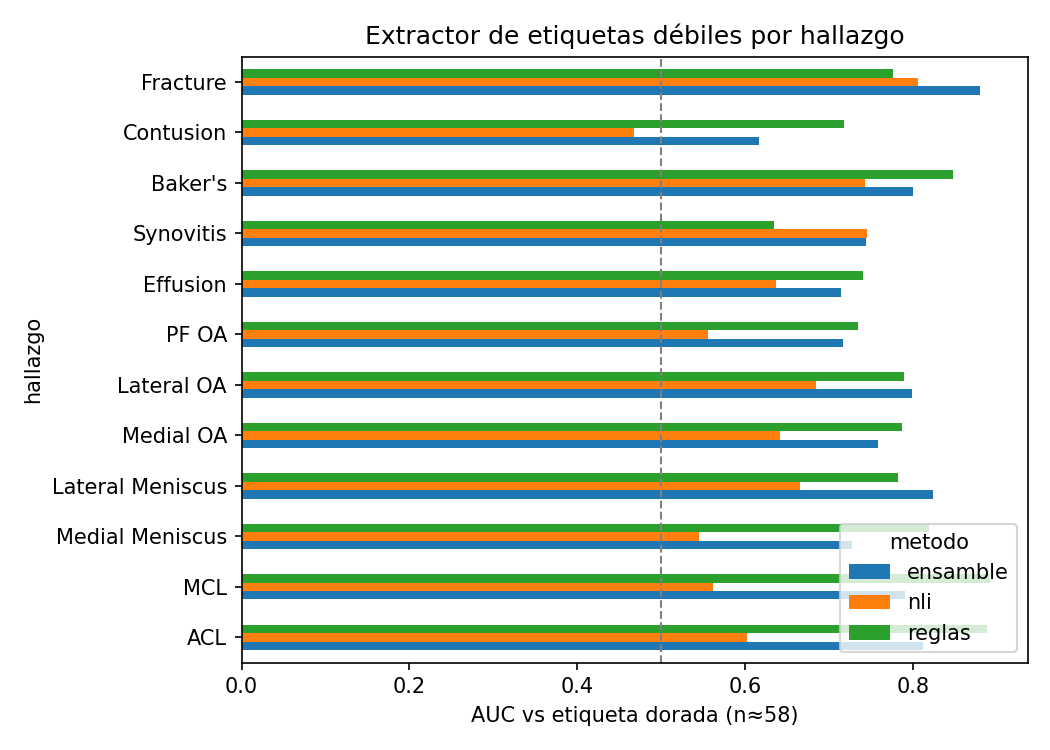

/kaggle/working/p1/06_resultados/figuras/07_atencion_A1_scratch.png


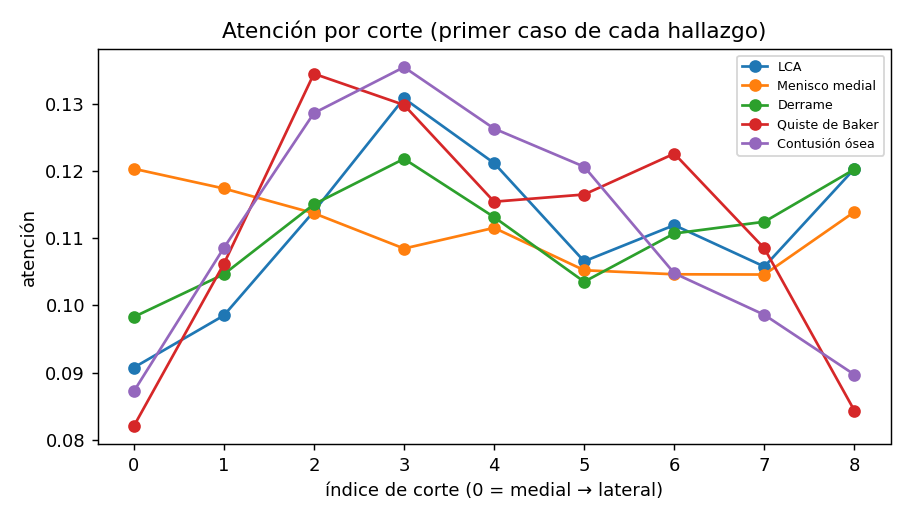

/kaggle/working/p1/06_resultados/figuras/07_atencion_A2_resnet50.png


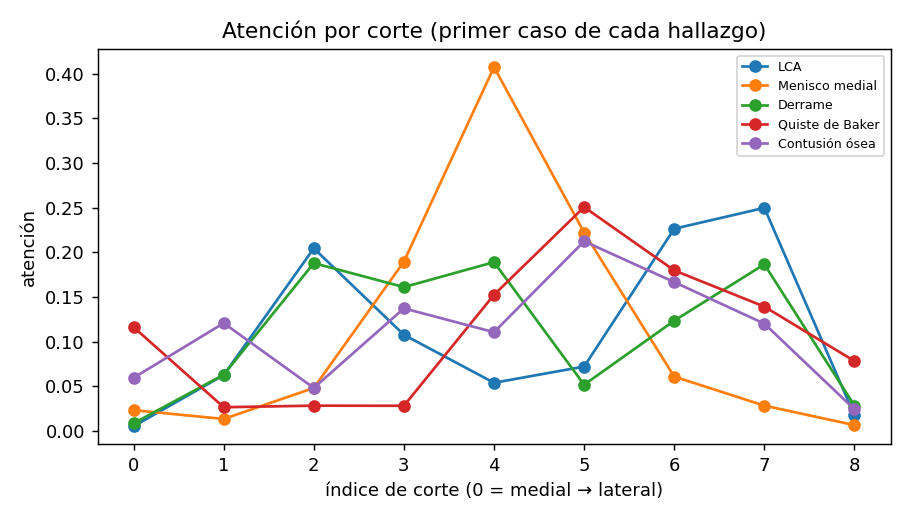

/kaggle/working/p1/06_resultados/figuras/07_gradcam_A1_scratch.png


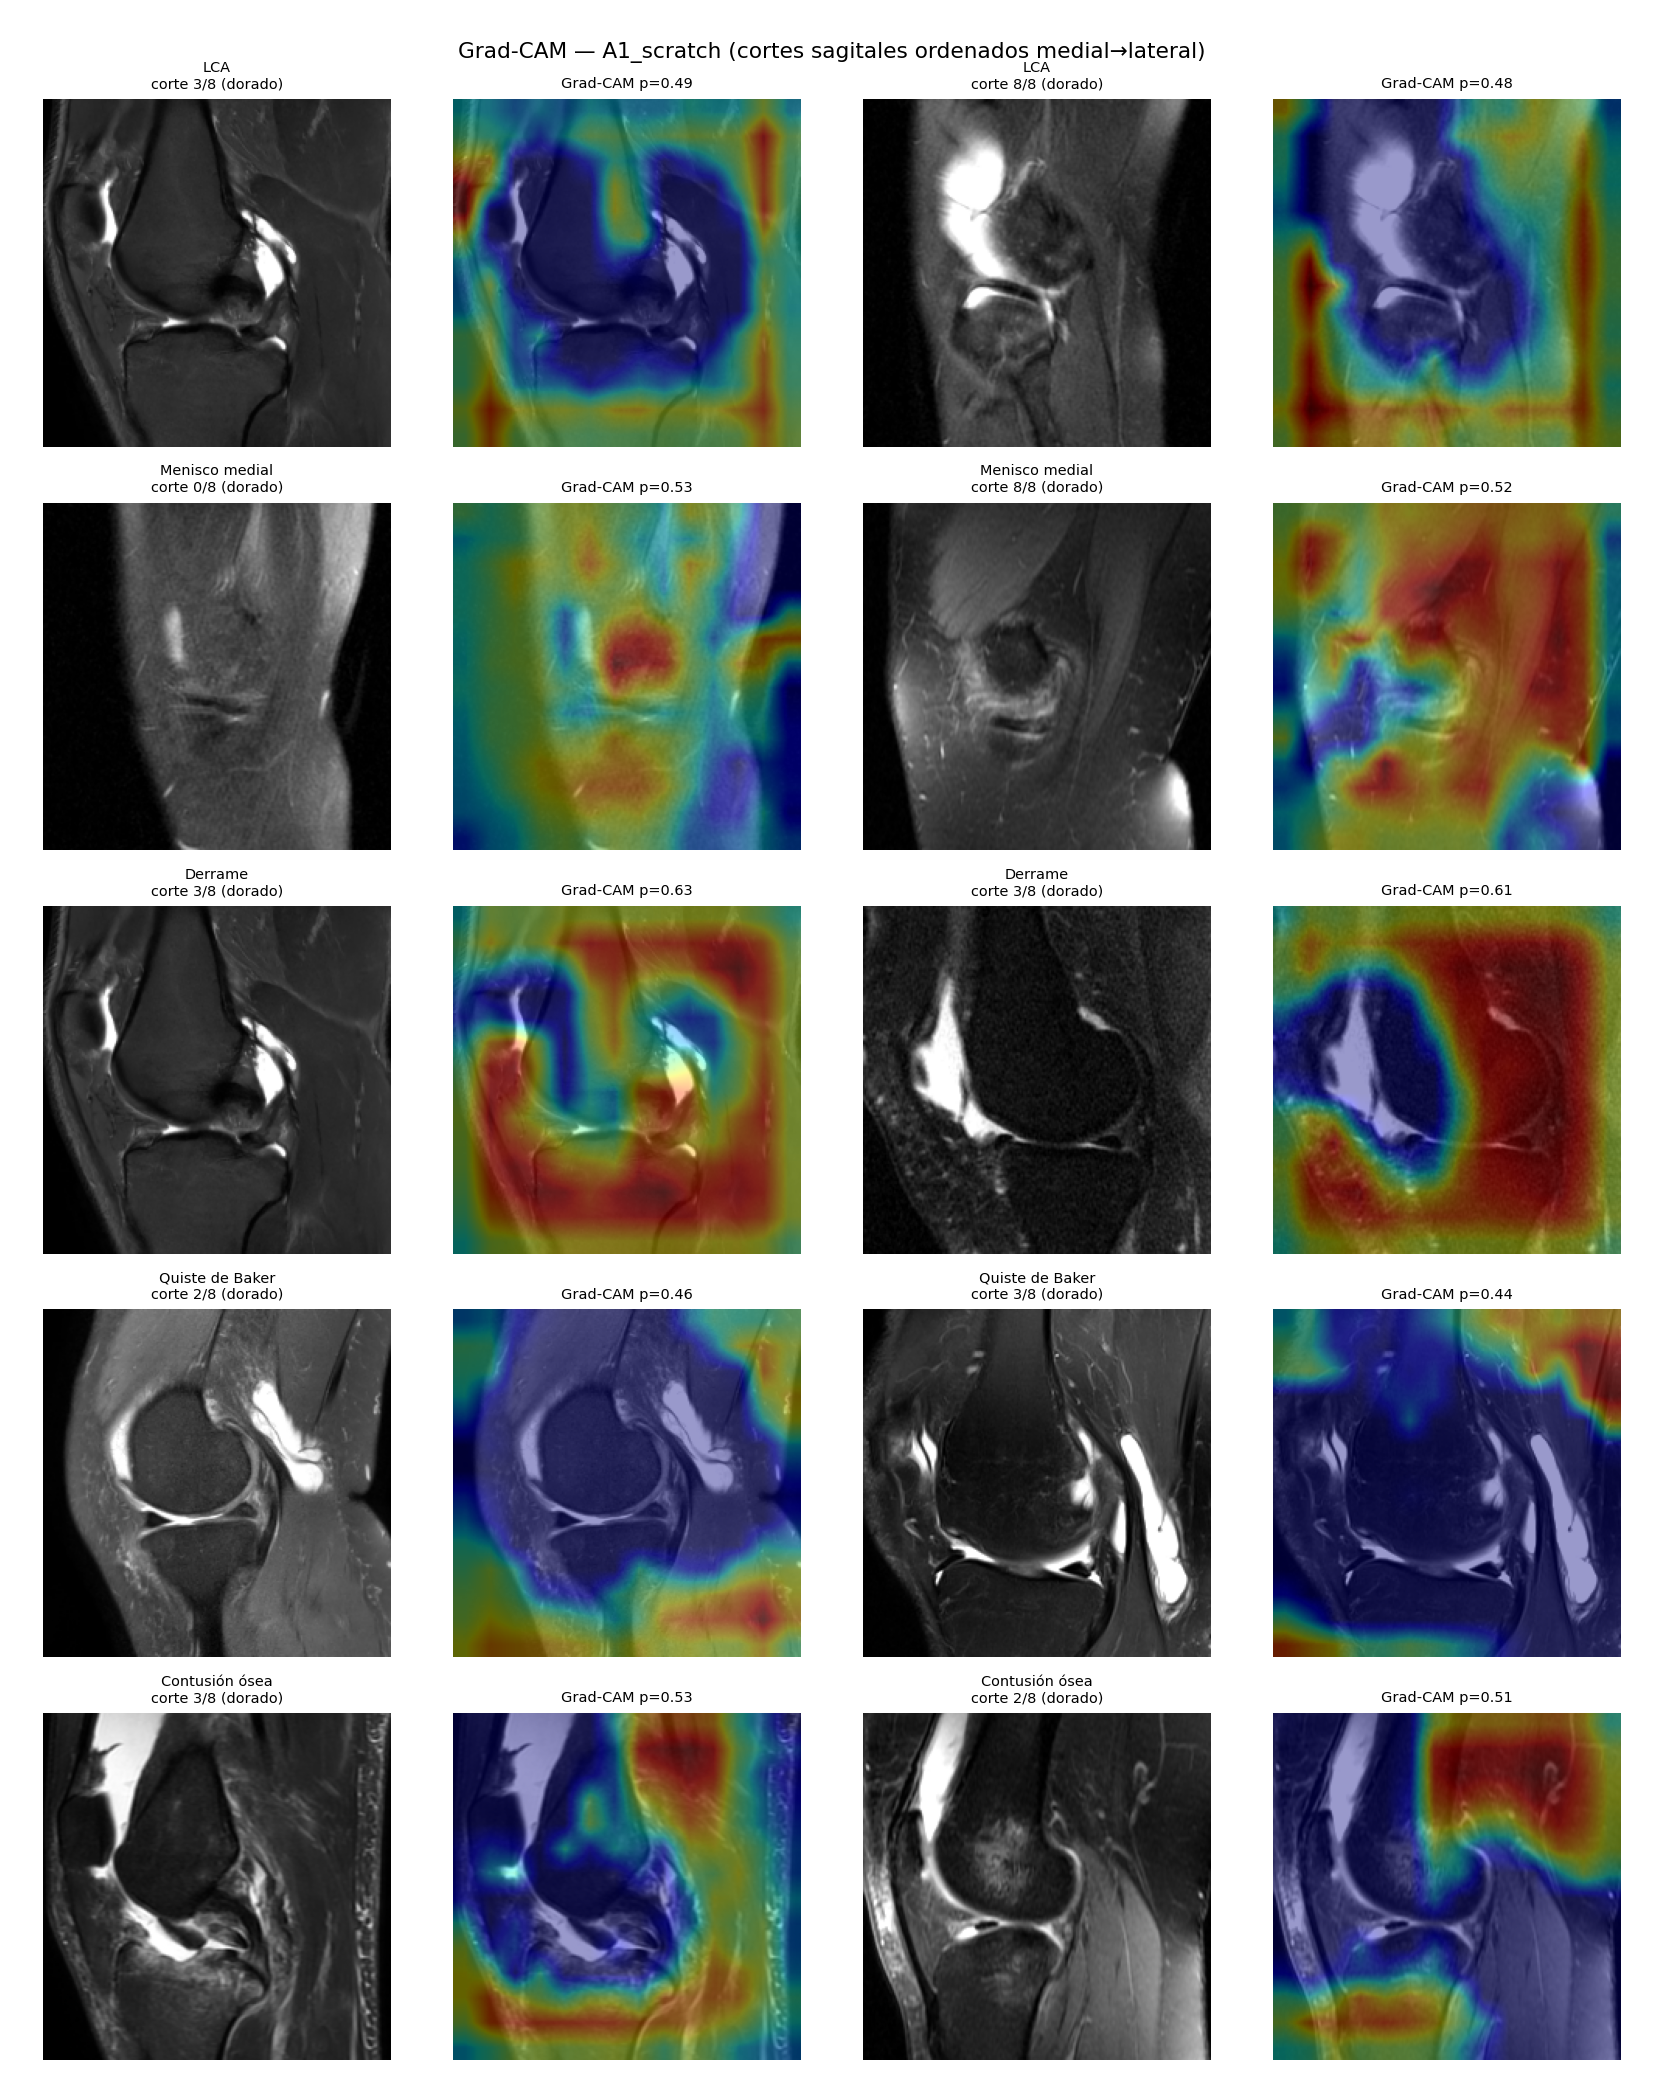

/kaggle/working/p1/06_resultados/figuras/07_gradcam_A2_resnet50.png


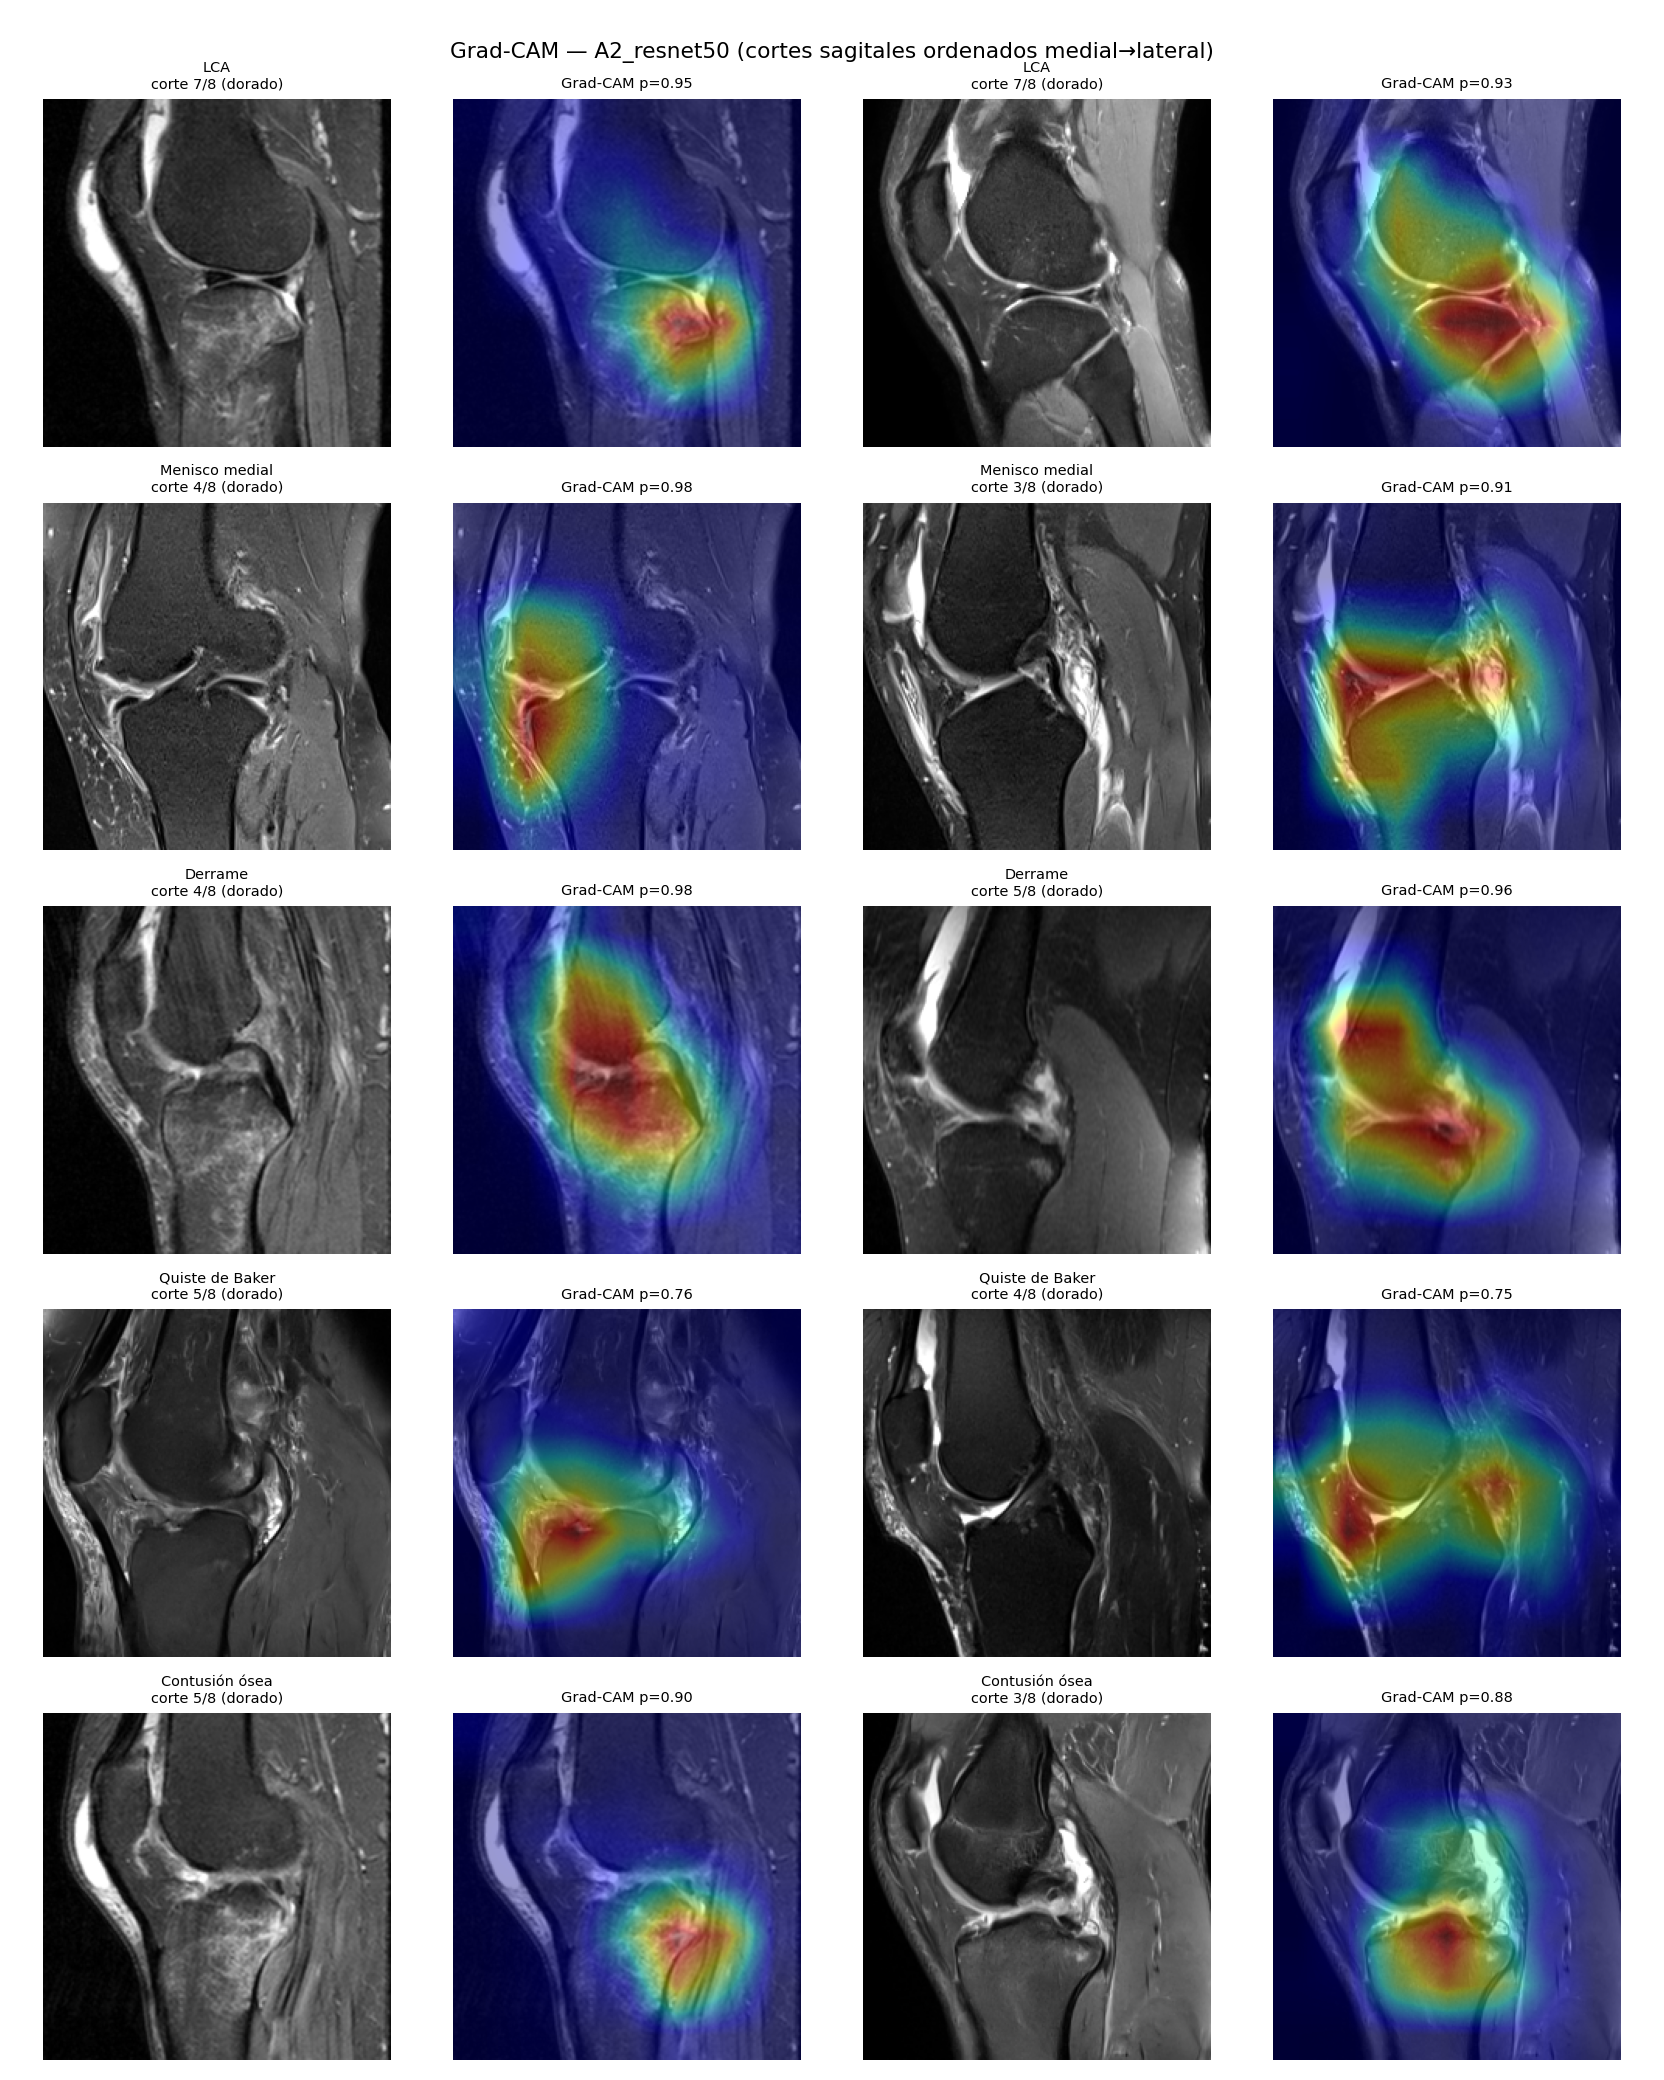

/kaggle/working/p1/06_resultados/figuras/08_auc_heatmap.png


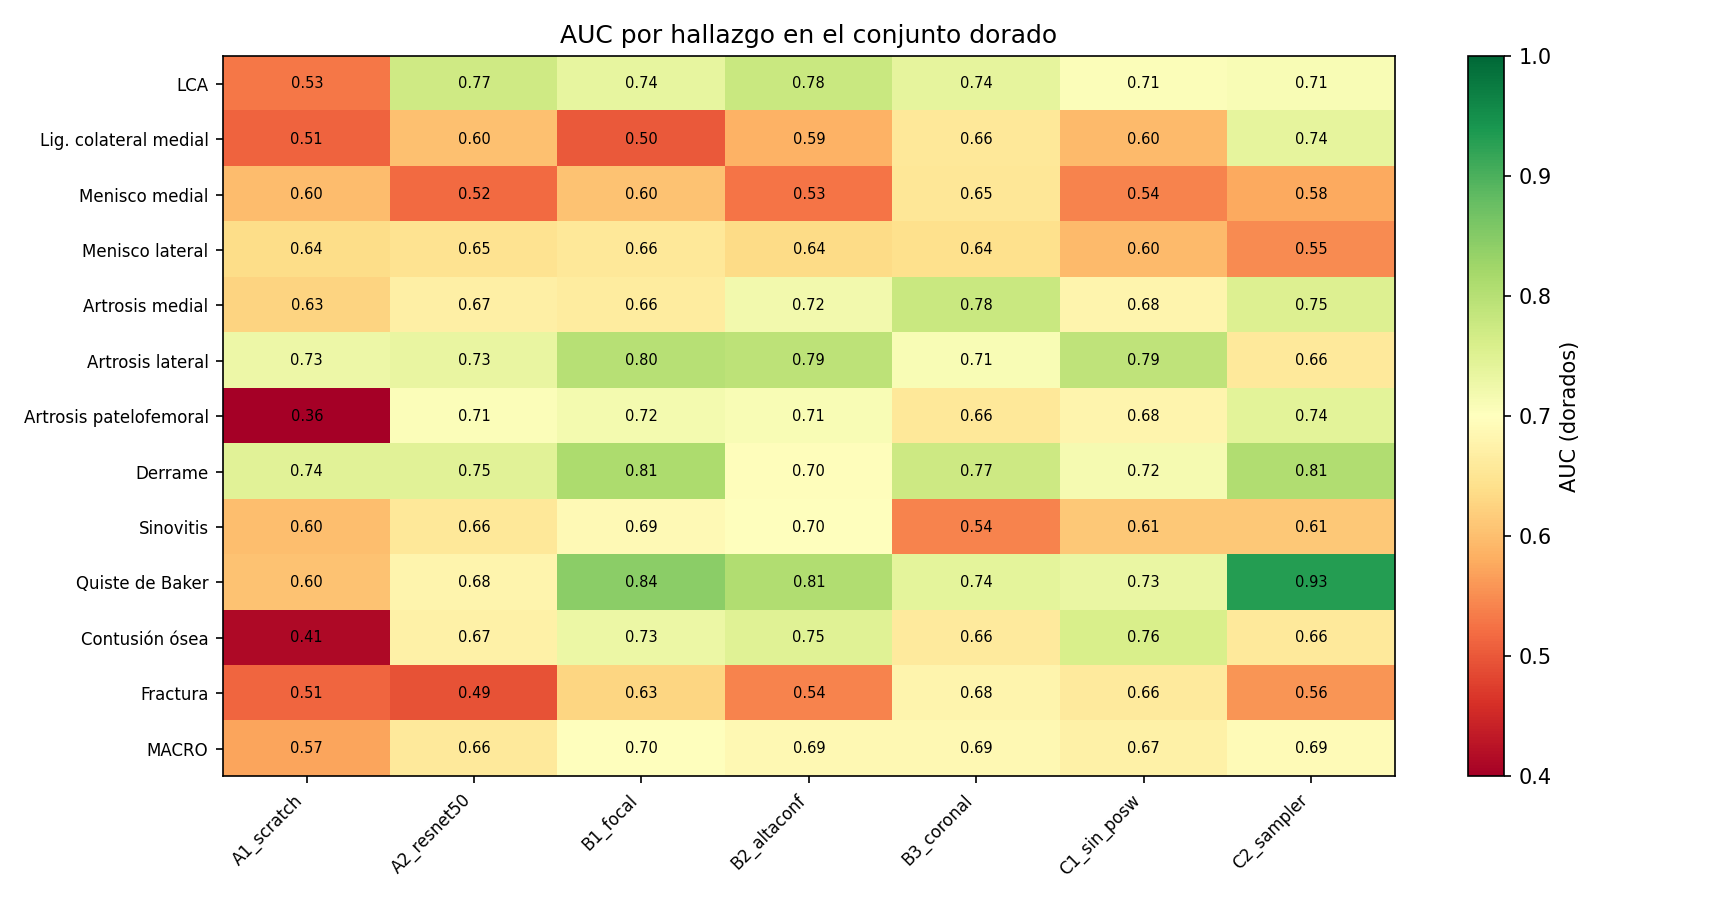

/kaggle/working/p1/06_resultados/figuras/08_curvas_entrenamiento.png


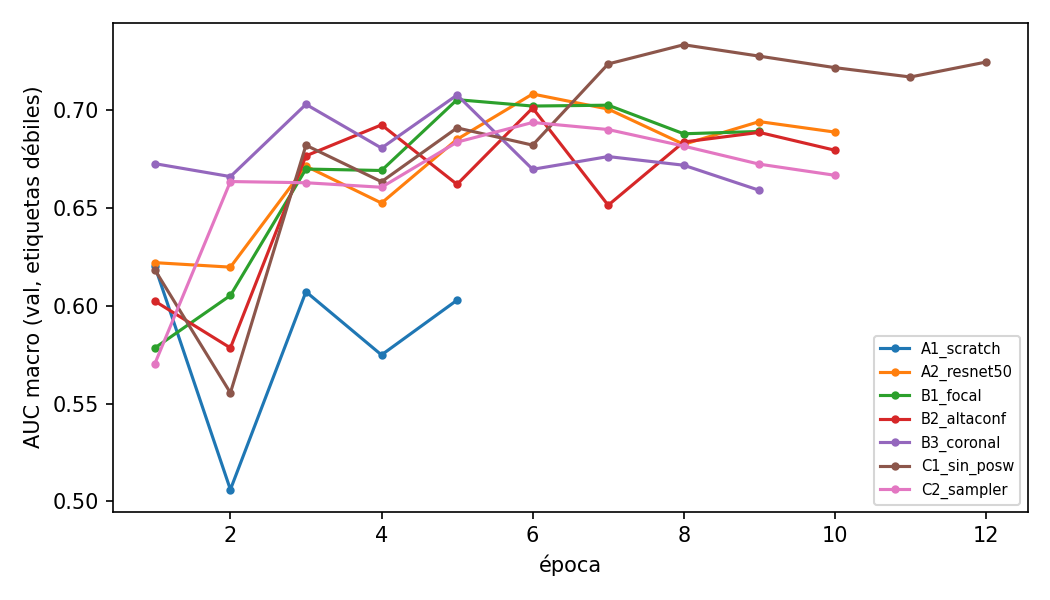

In [9]:
from IPython.display import Image, display, Markdown
display(Markdown(open('/kaggle/working/p1/06_resultados/08_comparacion_runs.md').read()))
for f in sorted(glob.glob('/kaggle/working/p1/06_resultados/figuras/*.png')):
    print(f); display(Image(f, width=700))

## 6. Descargar resultados (sin caché ni pesos)

In [10]:
%cd /kaggle/working/p1
!zip -qr /kaggle/working/p1_resultados.zip 02_logs 05_datos 06_resultados -x "*.pt"
!ls -lh /kaggle/working/p1_resultados.zip

/kaggle/working/p1
-rw-r--r-- 1 root root 5.7M Oct 30 08:44 /kaggle/working/p1_resultados.zip
